# Lab 7 of 8

In [1]:
import json
import os
import site
import subprocess
import sys
import zipfile
from pathlib import Path

# Let NumPy and PyTorch share the OpenMP runtime on Windows.
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score

# PyTorch: import it, or install the CPU build into this kernel's Python if it is missing.
try:
    import torch
except ModuleNotFoundError:
    print("PyTorch is not installed for", sys.executable, "- installing it once (a few hundred MB) ...")
    pip = [sys.executable, "-m", "pip", "install", "torch"]
    if subprocess.run(pip + ["--index-url", "https://download.pytorch.org/whl/cpu"]).returncode != 0:
        subprocess.run(pip, check=True)
    site.addsitedir(site.getusersitepackages())
    import torch
from torch import nn

# Use a GPU when PyTorch can see one; otherwise the CPU.
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

torch.manual_seed(42)

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

print("Python", sys.version.split()[0], "at", sys.executable)
print("PyTorch", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")

Python 3.11.3 at C:\Users\intan\python.exe
PyTorch 2.15.0+cpu | device: cpu 


## Part A: Images as tensors

fit: torch.Size([2868, 1, 8, 8])  validation: torch.Size([955, 1, 8, 8])  test: torch.Size([1797, 1, 8, 8])


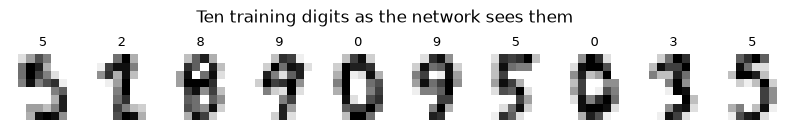

In [2]:
columns = [f"pixel_{i}" for i in range(64)] + ["label"]
with zipfile.ZipFile(DATA / "optical_recognition_handwritten_digits.zip") as archive:
    members = {Path(name).name: name for name in archive.namelist()}
    train = pd.read_csv(archive.open(members["optdigits.tra"]), header=None, names=columns)
    test = pd.read_csv(archive.open(members["optdigits.tes"]), header=None, names=columns)

def to_tensors(frame):
    X = torch.tensor(frame.drop(columns="label").to_numpy(), dtype=torch.float32)
    X = X.reshape(-1, 1, 8, 8) / 16.0
    y = torch.tensor(frame["label"].to_numpy(), dtype=torch.long)
    return X.to(DEVICE), y.to(DEVICE)

X_dev, y_dev = to_tensors(train)
X_test, y_test = to_tensors(test)

perm = torch.randperm(len(X_dev), generator=torch.Generator().manual_seed(42))
n_val = len(X_dev) // 4
X_val, y_val = X_dev[perm[:n_val]], y_dev[perm[:n_val]]
X_fit, y_fit = X_dev[perm[n_val:]], y_dev[perm[n_val:]]
print("fit:", X_fit.shape, " validation:", X_val.shape, " test:", X_test.shape)

fig, axes = plt.subplots(1, 10, figsize=(10, 1.4))
for ax, image, label in zip(axes, X_fit[:10], y_fit[:10]):
    ax.imshow(image[0].cpu(), cmap="gray_r")
    ax.set_title(int(label), fontsize=9)
    ax.axis("off")
plt.suptitle("Ten training digits as the network sees them", y=1.05)
plt.show()

## Part B: A first neural network and the training loop

In [3]:
def make_mlp():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(64, 128), nn.ReLU(),
        nn.Linear(128, 10),
    )

mlp = make_mlp().to(DEVICE)
print(mlp)
print("trainable weights:", sum(p.numel() for p in mlp.parameters()))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=64, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
trainable weights: 9610


In [4]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(dim=1) == y).float().mean().item()

def train_classifier(model, X, y, X_v, y_v, epochs=20, lr=3e-3, batch_size=32):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = {"train": [], "validation": []}
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(X))
        for start in range(0, len(X), batch_size):
            batch = order[start:start + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(X[batch]), y[batch])
            loss.backward()
            optimizer.step()
        history["train"].append(accuracy(model, X, y))
        history["validation"].append(accuracy(model, X_v, y_v))
    return history

torch.manual_seed(42)
mlp_history = train_classifier(mlp, X_fit, y_fit, X_val, y_val)
print("dense network: validation accuracy =", round(mlp_history["validation"][-1], 4))

dense network: validation accuracy = 0.9759


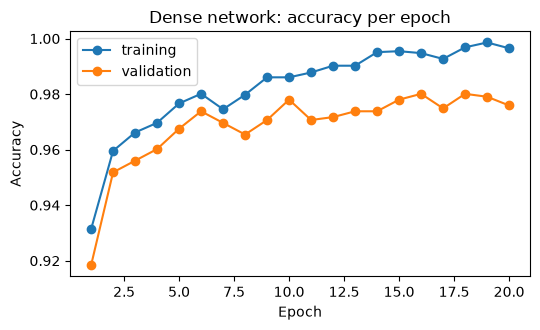

In [5]:
def plot_history(history, title):
    plt.figure(figsize=(5.5, 3.4))
    plt.plot(range(1, len(history["train"]) + 1), history["train"], marker="o", label="training")
    plt.plot(range(1, len(history["validation"]) + 1), history["validation"],
             marker="o", label="validation")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(mlp_history, "Dense network: accuracy per epoch")

## Part C: A convolutional network

In [6]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * 2 * 2, 64), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(64, 10),
    )

cnn = make_cnn().to(DEVICE)
print("trainable weights:", sum(p.numel() for p in cnn.parameters()))

sample = X_fit[:1]
for layer in cnn:
    sample = layer(sample)
    if isinstance(layer, (nn.Conv2d, nn.MaxPool2d, nn.Flatten, nn.Linear)):
        print(f"{layer.__class__.__name__:10s} -> {tuple(sample.shape[1:])}")

trainable weights: 13706
Conv2d     -> (16, 8, 8)
MaxPool2d  -> (16, 4, 4)
Conv2d     -> (32, 4, 4)
MaxPool2d  -> (32, 2, 2)
Flatten    -> (128,)
Linear     -> (64,)
Linear     -> (10,)


CNN: validation accuracy = 0.9822


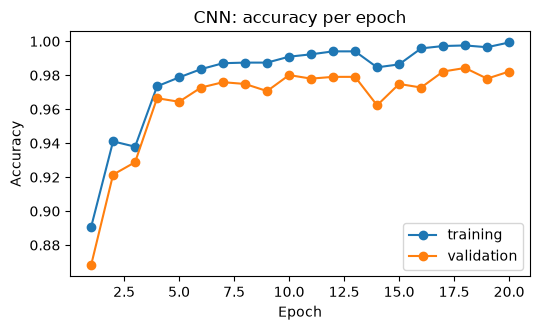

In [7]:
torch.manual_seed(42)
cnn_history = train_classifier(cnn, X_fit, y_fit, X_val, y_val)
print("CNN: validation accuracy =", round(cnn_history["validation"][-1], 4))
plot_history(cnn_history, "CNN: accuracy per epoch")

The official test file is opened **once** for each model. The Lab 4 value below is the PCA-plus-logistic accuracy on the same file. If your own Lab 4 notebook printed a different number, replace `0.9477` with yours.

logistic on PCA (Lab 4)    test accuracy = 0.9477
dense network              test accuracy = 0.9583
CNN                        test accuracy = 0.9711


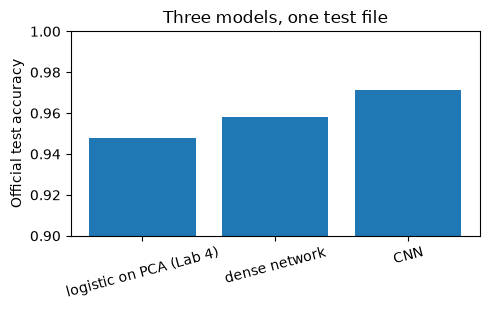

In [8]:
test_scores = {
    "logistic on PCA (Lab 4)": 0.9477,
    "dense network": accuracy(mlp, X_test, y_test),
    "CNN": accuracy(cnn, X_test, y_test),
}
for name, value in test_scores.items():
    print(f"{name:26s} test accuracy = {value:.4f}")

plt.figure(figsize=(5, 3.2))
plt.bar(list(test_scores), list(test_scores.values()))
plt.ylim(0.9, 1.0)
plt.ylabel("Official test accuracy")
plt.title("Three models, one test file")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

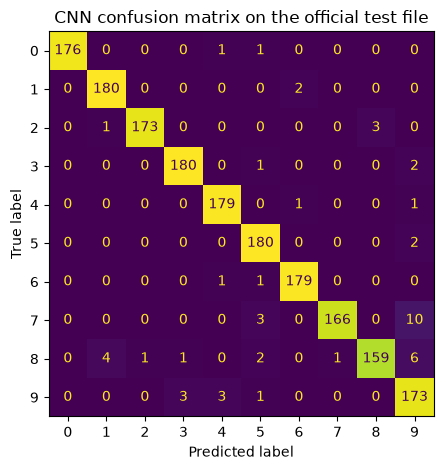

number of CNN mistakes on the test file: 52


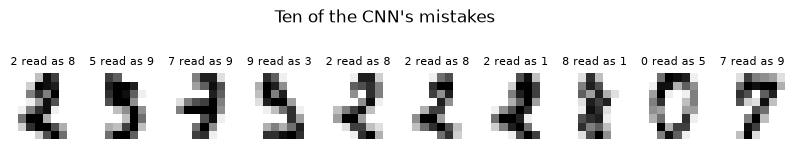

In [9]:
cnn.eval()
with torch.no_grad():
    test_pred = cnn(X_test).argmax(dim=1)

ConfusionMatrixDisplay.from_predictions(y_test.cpu().numpy(), test_pred.cpu().numpy(), colorbar=False)
plt.title("CNN confusion matrix on the official test file")
plt.tight_layout()
plt.show()

wrong = torch.nonzero(test_pred != y_test).flatten()[:10]
print("number of CNN mistakes on the test file:", int((test_pred != y_test).sum()))
fig, axes = plt.subplots(1, len(wrong), figsize=(10, 1.6))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(X_test[i, 0].cpu(), cmap="gray_r")
    ax.set_title(f"{int(y_test[i])} read as {int(test_pred[i])}", fontsize=8)
    ax.axis("off")
plt.suptitle("Ten of the CNN's mistakes", y=1.1)
plt.show()

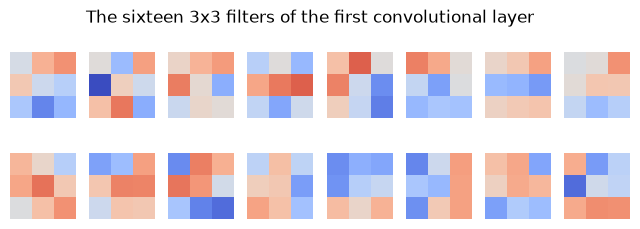

In [10]:
filters = cnn[0].weight.detach().cpu()[:, 0]
fig, axes = plt.subplots(2, 8, figsize=(8, 2.4))
for ax, kernel in zip(axes.flat, filters):
    ax.imshow(kernel, cmap="coolwarm", vmin=-filters.abs().max(), vmax=filters.abs().max())
    ax.axis("off")
plt.suptitle("The sixteen 3x3 filters of the first convolutional layer", y=1.02)
plt.show()

## Part D: Save the weights with a card

In [11]:
weights_path = MODELS / "digits_cnn.pt"
torch.save(cnn.state_dict(), weights_path)

card = {
    "task": "classify 8x8 handwritten digits (0-9)",
    "input": "tensor of shape (n, 1, 8, 8), pixel values divided by 16",
    "architecture": "make_cnn() in Lab 7: conv16-pool-conv32-pool-dense64-dense10",
    "training": {"epochs": 20, "learning_rate": 3e-3, "batch_size": 32, "seed": 42},
    "official_test_accuracy": round(test_scores["CNN"], 4),
    "torch_version": torch.__version__,
    "trained_on": str(DEVICE),
}
(MODELS / "digits_cnn_card.json").write_text(json.dumps(card, indent=2))

restored = make_cnn().to(DEVICE)
restored.load_state_dict(torch.load(weights_path, map_location=DEVICE, weights_only=True))
restored.eval()
with torch.no_grad():
    same = torch.equal(restored(X_test).argmax(dim=1), test_pred)

size_kb = weights_path.stat().st_size / 1024
print(f"saved {weights_path.name} ({size_kb:.0f} KB); reload reproduces predictions: {same}")

saved digits_cnn.pt (57 KB); reload reproduces predictions: True


## Self Practice

5 epochs : final validation accuracy = 0.9665
40 epochs: final validation accuracy = 0.9749
40 epochs: best validation accuracy = 0.9843 at epoch 33


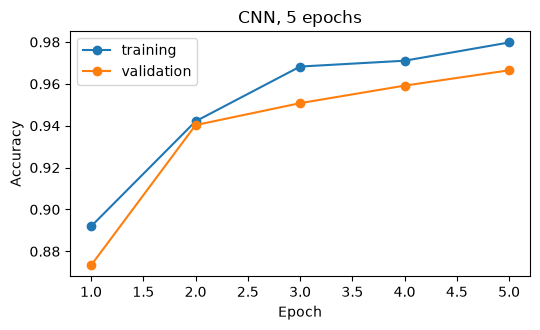

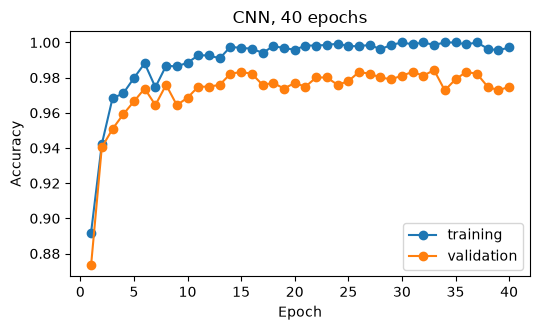

In [12]:
# Part 1: 5 versus 40 epochs, judged on validation accuracy only.
torch.manual_seed(42)
cnn_5 = make_cnn().to(DEVICE)
hist_5 = train_classifier(cnn_5, X_fit, y_fit, X_val, y_val, epochs=5)

torch.manual_seed(42)
cnn_40 = make_cnn().to(DEVICE)
hist_40 = train_classifier(cnn_40, X_fit, y_fit, X_val, y_val, epochs=40)

print(f"5 epochs : final validation accuracy = {hist_5['validation'][-1]:.4f}")
print(f"40 epochs: final validation accuracy = {hist_40['validation'][-1]:.4f}")
best_epoch = int(np.argmax(hist_40["validation"])) + 1
print(f"40 epochs: best validation accuracy = {max(hist_40['validation']):.4f} at epoch {best_epoch}")

plot_history(hist_5, "CNN, 5 epochs")
plot_history(hist_40, "CNN, 40 epochs")

trainable weights, one block: 17258 | two blocks: 13706
one conv block : validation accuracy = 0.9780
two conv blocks: validation accuracy = 0.9822


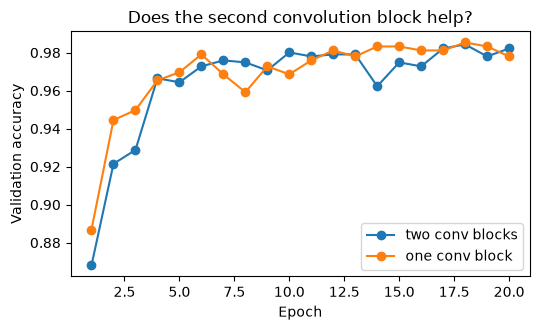

In [13]:
# Part 2: remove the second conv/ReLU/pool block; flatten becomes 16 x 4 x 4 = 256.
def make_small_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 4 * 4, 64), nn.ReLU(), nn.Dropout(0.2),
        nn.Linear(64, 10),
    )

torch.manual_seed(42)
small_cnn = make_small_cnn().to(DEVICE)
print("trainable weights, one block:", sum(p.numel() for p in small_cnn.parameters()),
      "| two blocks:", sum(p.numel() for p in cnn.parameters()))
small_history = train_classifier(small_cnn, X_fit, y_fit, X_val, y_val)

print(f"one conv block : validation accuracy = {small_history['validation'][-1]:.4f}")
print(f"two conv blocks: validation accuracy = {cnn_history['validation'][-1]:.4f}")

plt.figure(figsize=(5.5, 3.4))
plt.plot(range(1, 21), cnn_history["validation"], marker="o", label="two conv blocks")
plt.plot(range(1, 21), small_history["validation"], marker="o", label="one conv block")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Does the second convolution block help?")
plt.legend()
plt.tight_layout()
plt.show()